# 學生學習與作業版｜任務 5：分組統計與比較

**姓名：** 楊采慈　**學號／組別：** C114118137　**完成日期：** 11/19

**學習目標：** 以分組筆數、平均數與中位數比較類別，避免直接推論因果。

本單元與教師版「任務 5」相同標題、資料、教學順序與範例；除了明確標示的作業與填空，其餘教師版教材內容保留。對照重點：程式填空對應教師版「5.1 分組」。

### 如何完成
1. 先閱讀觀念與執行資料準備；各單元可以獨立啟動，不需要依賴上一單元的變數。
2. **💻 P 作業**：在指定程式 cell 補上 `____`，可先用提供的 Vibe Coding 提示詞詢問 AI。補完再執行，並執行後面的驗證 cell。未填時出現 `NameError` 是預期現象，先完成填空再繼續。
3. **📝 Q 作業**：查詢 AI、比較教材內容，填寫緊接的文字作答區；請記錄實際提示詞、自己的解釋與查證方式。
4. **🎯 M 小任務**：在任務 4、8、12、16 將前面幾單元整合成可執行的成果。不要只交 AI 回覆，要交實際程式、輸出與自己的解釋。
5. 把 Notebook 存到自己的 Google 雲端硬碟，完成後下載／依教師指示繳交 `.ipynb`；小任務保留輸出、文字與 AI 使用紀錄。

**案例限制：** 本資料是公式生成的 60 筆模擬紀錄，不能推論真實學生或因果。缺失與 15 小時值在計分後加入。預測時欄位可得性是假設；全部資料已在前半段探索，後續切出的測試集僅示範流程，不能視為完全獨立的新資料。

**完成檢核：** 本單元有 1 項程式填空、2 項 AI 查詢作答；若是任務 4、8、12、16，另外有 1 項整合小任務。請保留自己的輸出、回答和驗證紀錄。


## 共用資料準備
以下在記憶體重建與既有教材相同的資料。執行後可以直接開始本單元；不會覆寫 CSV。


In [1]:
# 匯入套件：numpy 建立隨機資料，pandas 管理表格，pyplot 繪圖
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# 固定種子，並維持呼叫順序，以重現原教材的 60 筆模擬資料
rng = np.random.default_rng(42)
n = 60
departments = ["資訊管理", "企業管理", "金融管理"]
# 每個字典鍵是一個欄位；對應的值是 60 名學生的資料
data = {
    "student_id": range(1, n + 1),
    "department": rng.choice(departments, n),
    "sleep_hours": rng.normal(6.7, 1.1, n).round(1),
    "screen_time_hours": rng.normal(5.0, 1.5, n).clip(1, 10).round(1),
    "study_hours": rng.normal(2.5, 1.0, n).clip(0.5, 6).round(1),
    "attendance_rate": rng.normal(88, 8, n).clip(60, 100).round(0),
}
df = pd.DataFrame(data)
# 成績依設定公式與隨機誤差建立；關係來自模擬規則，不能視為因果發現
noise = rng.normal(0, 5, n)
score = (50 + 3 * df["study_hours"] + 2 * df["sleep_hours"]
         - 1.2 * df["screen_time_hours"] + 0.15 * df["attendance_rate"] + noise)
df["quiz_score"] = score.clip(0, 100).round(0)
# 故意在計分後加入資料品質問題；無法從表格還原計分時原始值
df.loc[[5, 17], "sleep_hours"] = np.nan
df.loc[8, "screen_time_hours"] = 15.0
print("模擬資料形狀（列, 欄）：", df.shape)


模擬資料形狀（列, 欄）： (60, 7)


## 5.1 用 groupby 分組
**觀念說明：** 平均數必須與人數一起看；`count` 是非缺失數，`size` 是列數。本例科系隨機分配，沒有直接納入生成成績的公式。


## 💻 學生作業 05-P1｜Vibe Coding 程式填空
**對應教師版：** 任務 5「5.1 分組」的示範程式。

**任務：** 按 department 分組，彙總 quiz_score 的 count、mean、median，存成 summary。

**執行方式：** 找到下一個程式儲存格中的 `____`，使用自己撰寫或 AI 建議的程式補齊，保留其他已提供的程式與註解。補完後先執行該 cell，再執行緊接的自動檢查；後續單元內容可能依賴此變數。

**可使用的 Vibe Coding 提示詞：**
```text
我是 Python 與資料分析初學者，正在 Google Colab 使用 pandas、numpy、matplotlib 或 scikit-learn。
我的任務是：按 department 分組，彙總 quiz_score 的 count、mean、median，存成 summary。
請依我貼上的上下文，只協助補上 ____，保留指定變數名稱與後續程式，不修改原始 df。
請解釋每一步的作用，提供繁體中文註解及可手動驗證的方法。
不要虛構執行結果；如需額外資訊，先指出缺少什麼。
```
完成後記錄實際使用的提示詞與自己改動的地方。


In [ ]:
# 以科系分組，聚合成績的有效筆數、平均與中位數
summary = ____  # TODO：按科系分組，計算成績 count、mean、median
display(summary)
print("各組有效人數加總：", summary["count"].sum())
print("資料總人數：", len(df))
assert summary["count"].sum() == df["quiz_score"].count()


In [2]:
# 以科系分組，聚合成績的有效筆數、平均與中位數
summary = df.groupby("department")["quiz_score"].agg(["count", "mean", "median"])  # TODO：按科系分組，計算成績 count、mean、median
display(summary)
print("各組有效人數加總：", summary["count"].sum())
print("資料總人數：", len(df))
assert summary["count"].sum() == df["quiz_score"].count()


,count,mean,median
department,,,
企業管理,21,80.666667,81.0
資訊管理,15,79.733333,80.0
金融管理,24,76.583333,76.5


各組有效人數加總： 60
資料總人數： 60


### ✅ 作業 05-P1｜執行驗證
執行下方程式，並同時檢查上方實際輸出。自動檢查只涵蓋主要條件；如果圖表、說明或資料來源不符任務，仍需人工修正。


In [3]:
assert list(summary.columns) == ["count", "mean", "median"]
assert summary["count"].sum() == df["quiz_score"].count()
print("檢查通過：統計欄位與有效人數正確。")


檢查通過：統計欄位與有效人數正確。


### ✍️ 作業 05-P1｜我的完成紀錄
- 我實際使用的提示詞（若未使用 AI 請註明）：我是 Python 與資料分析初學者，正在 Google Colab 使用 pandas、numpy、matplotlib 或 scikit-learn。
我的任務是：按 department 分組，彙總 quiz_score 的 count、mean、median，存成 summary。
請依我貼上的上下文，只協助補上 ____，保留指定變數名稱與後續程式，不修改原始 df。
請解釋每一步的作用，提供繁體中文註解及可手動驗證的方法。
不要虛構執行結果；如需額外資訊，先指出缺少什麼。
- 我補上的程式在做什麼：依 department 各值將列分成群組，對每組中非 NaN 的 quiz_score 計算 count（有效筆數）、mean（平均）、median（中位數），回傳以 department 為索引、欄名為 count/mean/median 的新 DataFrame，不修改原始 df。
- 執行或驗證遇到的問題與修正：成功執行，未遇到錯誤。
- 檢查結果及我如何確認：檢查通過。透過上方執行驗證程式確認。


## 📝 學生作業 05-Q1｜AI 查詢與作答：分組比較
**任務：** 為什麼比較科系平均成績時，也要檢查每組有效筆數？

**可使用的 AI 提示詞：**
```text
我是 Python 與資料分析初學者。請用小樣本例子解釋分組平均數與組別人數、缺失值的關係。
請使用繁體中文、台灣常用名詞，分步解釋，並提出我可以自行驗證的一個例子；不要假設我的程式輸出。
```
先閱讀教材，再詢問 AI。請記錄工具名稱、實際提示詞；若 AI 提供資料來源，記錄可查證的網址／文件名稱與日期，並自行檢查，無法查證時寫「尚未查證」。不要提供真實個資。


### ✍️ 作業 05-Q1 專用作答區：請雙擊此文字儲存格填寫
- AI 工具及實際提示詞：kklc。我是 Python 與資料分析初學者。請用小樣本例子解釋分組平均數與組別人數、缺失值的關係。
請使用繁體中文、台灣常用名詞，分步解釋，並提出我可以自行驗證的一個例子；不要假設我的程式輸出。
- AI 回答重點（請自行整理）：
  1. count 只算非缺值，mean 的分母是有效筆數而非名單人數
  2. 組越小人數權重越大，平均越容易被單筆左右
  3. 平均相同不代表分布相同，所以要連 count 與 median 一起看
  4. groupby 預設丢掉分組欄位缺值的列，會造成加總對不上。
- 我的理解與具體例子：1.平均數只由「有效筆數」決定，缺值會被無聲排除 2.小樣本的平均極不穩定，每個人的權重極大 3.平均數相同不代表分布相同 4.比較才有「可解釋性」
- 查證來源／方式及日期（無法查證請註明）：尚未查證
- 我檢查或修正 AI 回答的地方：實際執行程式碼後全部符合預期。


## 5.2 長條圖與資料核對
圖表顯示各組平均，不顯示各組個別差異；標籤使用英文代碼，並用表格提供中英文對照。


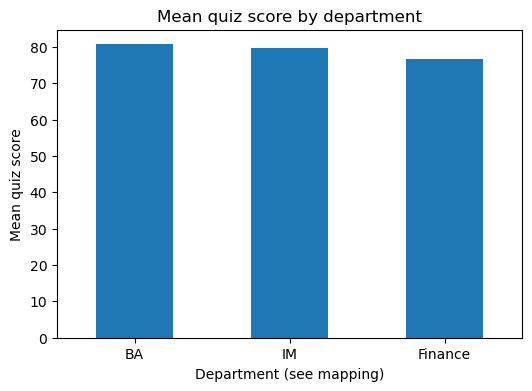

代碼對照： {'資訊管理': 'IM', '企業管理': 'BA', '金融管理': 'Finance'}


In [4]:
# 重建圖表顯示用資料，沒有改動原始 department
english_names = {"資訊管理": "IM", "企業管理": "BA", "金融管理": "Finance"}
means = summary["mean"].copy()
means.index = [english_names[name] for name in means.index]
means.plot(kind="bar", figsize=(6, 4), rot=0)
plt.title("Mean quiz score by department")
plt.xlabel("Department (see mapping)")
plt.ylabel("Mean quiz score")
plt.show()
print("代碼對照：", english_names)


## 📝 學生作業 05-Q2｜AI 查詢與作答：關聯與因果
**任務：** 本例不同科系的平均分數不同，能否證明科系造成差異？

**可使用的 AI 提示詞：**
```text
我是 Python 與資料分析初學者。請根據「科系隨機生成，成績公式未使用科系」說明組間平均差不能直接推論因果。
請使用繁體中文、台灣常用名詞，分步解釋，並提出我可以自行驗證的一個例子；不要假設我的程式輸出。
```
先閱讀教材，再詢問 AI。請記錄工具名稱、實際提示詞；若 AI 提供資料來源，記錄可查證的網址／文件名稱與日期，並自行檢查，無法查證時寫「尚未查證」。不要提供真實個資。


In [7]:
import numpy as np

scores = df["quiz_score"].to_numpy(dtype=float)          # 60 個成績
observed = summary["mean"].max() - summary["mean"].min() # 你的觀察值（應為 4.08 左右）
print("觀察到的組平均差距：", round(observed, 3))

rng = np.random.default_rng(123)      # 固定種子，結果可重現
B = 5000
null = np.empty(B)
for b in range(B):
    p = rng.permutation(scores)       # 洗牌＝模擬「科系對成績無影響」
    m1, m2, m3 = p[:21].mean(), p[21:36].mean(), p[36:].mean()
    null[b] = max(m1, m2, m3) - min(m1, m2, m3)

print("無效果時，差距 ≥ 觀察值的比例：", f"{(null >= observed).mean():.1%}")
print("觀察值在虛設分佈的百分位：    ", f"{(null <= observed).mean():.1%}")

觀察到的組平均差距： 4.083
無效果時，差距 ≥ 觀察值的比例： 12.7%
觀察值在虛設分佈的百分位：     87.4%


### ✍️ 作業 05-Q2 專用作答區：請雙擊此文字儲存格填寫
- AI 工具及實際提示詞：kklc。我是 Python 與資料分析初學者。請根據「科系隨機生成，成績公式未使用科系」說明組間平均差不能直接推論因果。
請使用繁體中文、台灣常用名詞，分步解釋，並提出我可以自行驗證的一個例子；不要假設我的程式輸出。
- AI 回答重點（請自行整理）：
  1. 公式未用科系＝真實因果效果為 0，機制已知
  2. 樣本平均隨抽樣變異，小樣本（15～24 人）標準誤大
  3. 平均差只是關聯，因果需排除機會／混淆／反向因果，本例確認為機會
  4. ANOVA 顯著只拒絕「平均相等」，不指出原因；H0 為真時顯著即第一型錯誤
  5. 可用亂數化（洗牌）檢定把觀察差距放到虛設分佈中對照。
- 我的理解與具體例子：三系的樣本平均不同（ex.最高 80.67、最低 76.58），差距約 4.08 分，但依生成方式，科系不影響成績，此差距應歸因於抽樣變異。
- 查證來源／方式及日期（無法查證請註明）：尚未查證
- 我檢查或修正 AI 回答的地方：實際執行程式碼後全部符合預期。


## 5.3 解釋差異的限制
**討論：** 科系平均不同是否證明科系造成成績差距？不行；本例科系隨機產生、樣本有限，而且有其他學習欄位與隨機誤差。
**學生交付：** 列出每組人數、平均與中位數；依實際結果寫一項觀察及一項不能推論的結論。


## 延伸：size 與 count
`size` 包含欄位缺失的資料列；`count` 只數指定欄非缺失的值。科系比較若忽略有效筆數，容易對小組或缺失組作過度解讀。


In [5]:
# 比較每個科系的資料列數與睡眠欄有效數
all_rows = df.groupby("department").size().rename("rows")
valid_sleep = df.groupby("department")["sleep_hours"].count().rename("valid_sleep")
display(pd.concat([all_rows, valid_sleep], axis=1))
assert all_rows.sum() == len(df)


,rows,valid_sleep
department,,
企業管理,21,21
資訊管理,15,14
金融管理,24,23


## 本單元學習收束與 AI 使用紀錄

請學生先用自己的話解釋一個關鍵觀念，再指出一個執行結果及驗證方式。記錄：使用的提示詞、AI 回答中檢查或修改的地方、遇到的問題、修正後的證據與本資料限制。

**通用提示詞**：我是 Python 初學者，請逐步協助我完成上面的任務；每段程式加繁體中文註解，說明輸入、處理與輸出，提供兩項可實際執行的驗證，保留原始資料，不要虛構執行結果。
